# digits mnist

In [ ]:
# ================================================================
# CNN ON HANDWRITTEN MNIST (train.csv / test.csv)
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TRAIN_PATH = "/content/train.csv"     # change to your path
TEST_PATH = "/content/test.csv"       # change to your path
CLASS_NAMES = [str(d) for d in range(10)]
NUM_CLASSES = len(CLASS_NAMES)

# ================================================================
# STAGE A: LOADING AND PREPROCESSING THE IMAGE DATA
# ================================================================
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

def prepare(df):
    y = df["label"].values
    X = df.drop(columns=["label"]).values.astype("float32") / 255.0
    X = X.reshape((-1, 28, 28, 1))                     # rows -> 28x28 grayscale images
    return X, to_categorical(y, NUM_CLASSES), y

x_train, y_train, _ = prepare(train_df)
x_test, y_test, y_test_idx = prepare(test_df)

print("Train:", x_train.shape, " Test:", x_test.shape)

# Sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {train_df['label'].iloc[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST digits")
plt.tight_layout()
plt.show()

# ================================================================
# STAGE B: DEFINING THE MODEL'S ARCHITECTURE
# ================================================================
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),                       # 28x28 -> 14x14
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),                       # 14x14 -> 7x7
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

# ================================================================
# STAGE C: TRAINING THE MODEL
# ================================================================
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(x_train, y_train,
                    validation_split=0.1,
                    epochs=10,
                    batch_size=128,
                    verbose=1)

# ================================================================
# STAGE D: ESTIMATING THE MODEL'S PERFORMANCE
# ================================================================
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print("\nClassification Report:")
print(classification_report(y_test_idx, y_pred, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(y_test_idx, y_pred)
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), CLASS_NAMES)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix (MNIST CNN)")
plt.tight_layout()
plt.savefig("mnist_cnn_confusion.png", dpi=150)
plt.show()

# Training curves
epochs_range = range(1, len(history.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epochs_range, history.history["loss"], label="train_loss")
ax1.plot(epochs_range, history.history["val_loss"], label="val_loss")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True)
ax2.plot(epochs_range, history.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, history.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True)
fig.suptitle("CNN Training History on MNIST")
plt.tight_layout()
plt.savefig("mnist_cnn_training.png", dpi=150)
plt.show()

# cifar10

In [ ]:
# ================================================================
# CNN ON CIFAR-10 (cifar10.csv)
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = "/content/cifar10.csv"     # change to your path
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
NUM_CLASSES = len(CLASS_NAMES)

# ================================================================
# STAGE A: LOADING AND PREPROCESSING THE IMAGE DATA
# ================================================================
df = pd.read_csv(CSV_PATH)
label_col = "label" if "label" in df.columns else df.columns[0]
y = df[label_col].values.astype("int64")
pixel_cols = [c for c in df.columns if c != label_col and c.lower() != "id"]
X = df[pixel_cols].values.astype("float32")
assert X.shape[1] == 3072, f"Expected 3072 pixel columns, found {X.shape[1]}"

# Each row is 1024 red, 1024 green, 1024 blue -> (32, 32, 3) image
X = X.reshape((-1, 3, 32, 32)).transpose(0, 2, 3, 1) / 255.0

# 80/20 split, keeping class proportions
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print("Train:", x_train.shape, " Test:", x_test.shape)

# Sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(CLASS_NAMES[y_train[i]], fontsize=9)
    plt.axis("off")
plt.suptitle("Sample CIFAR-10 images")
plt.tight_layout()
plt.show()

# ================================================================
# STAGE B: DEFINING THE MODEL'S ARCHITECTURE
# ================================================================
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),                       # 32x32 -> 16x16
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),                       # 16x16 -> 8x8
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

# ================================================================
# STAGE C: TRAINING THE MODEL
# ================================================================
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(x_train, y_train_cat,
                    validation_split=0.1,
                    epochs=20,
                    batch_size=64,
                    verbose=1)

# ================================================================
# STAGE D: ESTIMATING THE MODEL'S PERFORMANCE
# ================================================================
test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix (CIFAR-10 CNN)")
plt.tight_layout()
plt.savefig("cifar10_cnn_confusion.png", dpi=150)
plt.show()

# Training curves
epochs_range = range(1, len(history.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epochs_range, history.history["loss"], label="train_loss")
ax1.plot(epochs_range, history.history["val_loss"], label="val_loss")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True)
ax2.plot(epochs_range, history.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, history.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True)
fig.suptitle("CNN Training History on CIFAR-10")
plt.tight_layout()
plt.savefig("cifar10_cnn_training.png", dpi=150)
plt.show()

# sign language mnist

TensorFlow version: 2.21.0
GPU available: []
Train CSV shape: (50000, 3073)
Train images: (50000, 32, 32, 3)  Test images: (50000, 32, 32, 3)


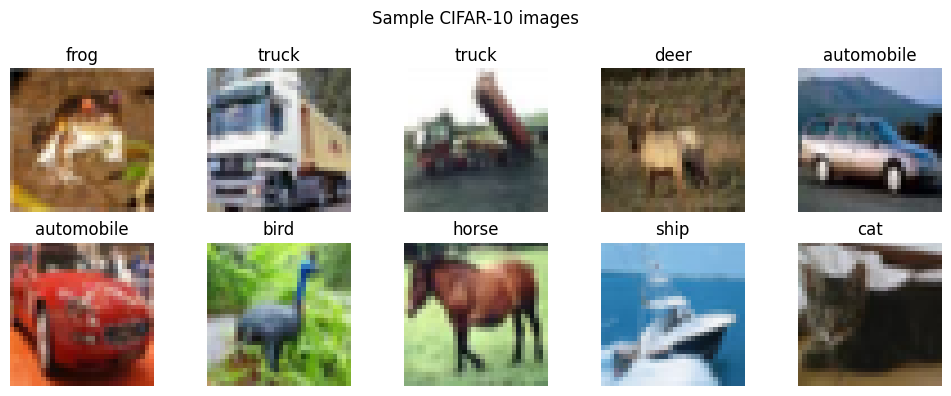

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,116,970 (4.26 MB)

 Trainable params: 1,116,970 (4.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 251s 353ms/step - accuracy: 0.3752 - loss: 1.6924 - val_accuracy: 0.4836 - val_loss: 1.4009
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 257s 345ms/step - accuracy: 0.5151 - loss: 1.3434 - val_accuracy: 0.5686 - val_loss: 1.2215
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 246s 350ms/step - accuracy: 0.5643 - loss: 1.2129 - val_accuracy: 0.6352 - val_loss: 1.0171
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 251s 335ms/step - accuracy: 0.6026 - loss: 1.1156 - val_accuracy: 0.6532 - val_loss: 0.9985
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 264s 337ms/step - accuracy: 0.6289 - loss: 1.0467 - val_accuracy: 0.6922 - val_loss: 0.8621
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 264s 340ms/step - accuracy: 0.6484 - loss: 0.9954 - val_accuracy: 0.7252 - val_loss: 0.8021
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 240s 340ms/step - accuracy: 0.6647 - loss: 0.9554 - val_accuracy: 0.7346 - val_loss: 0.7712
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 266s 345ms/step - accuracy: 0.6805 -

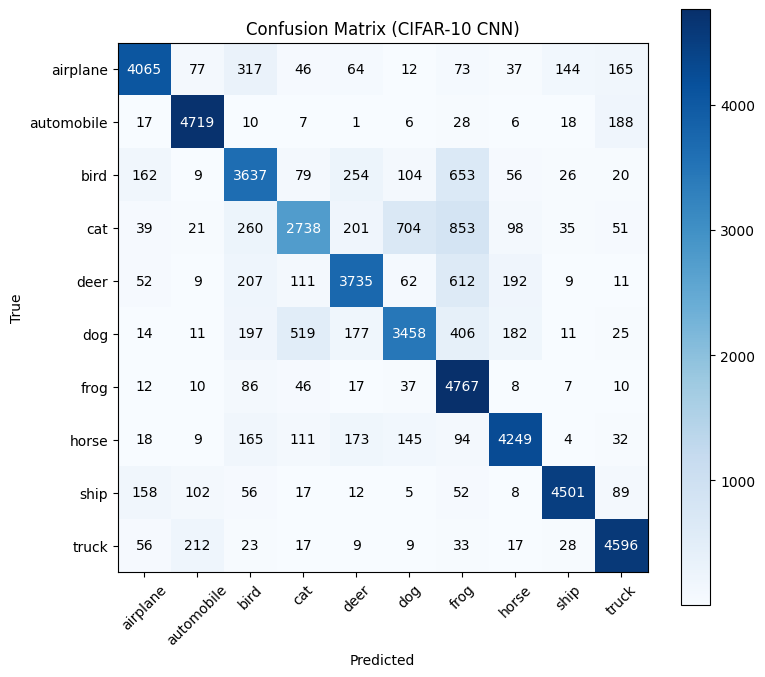

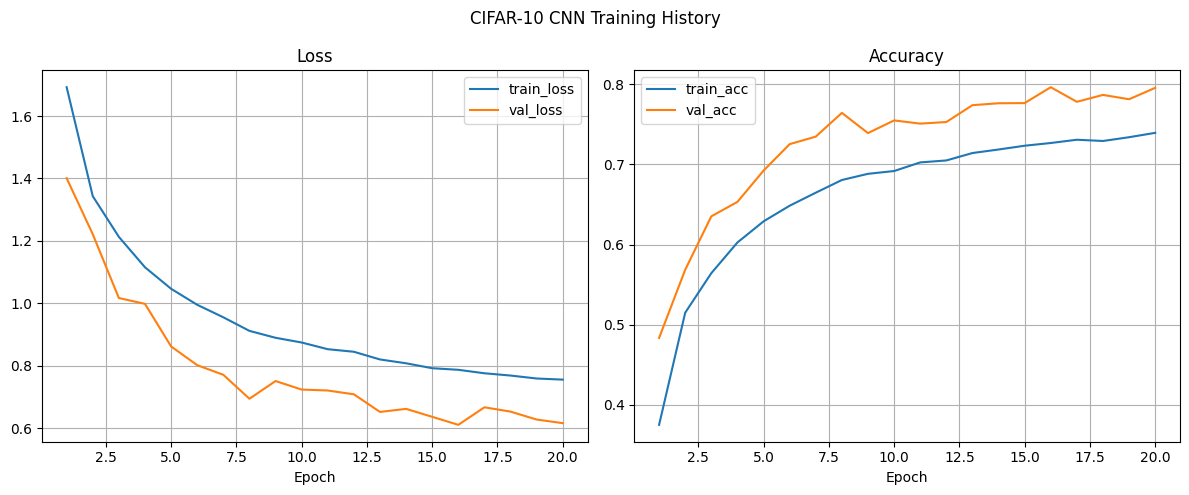

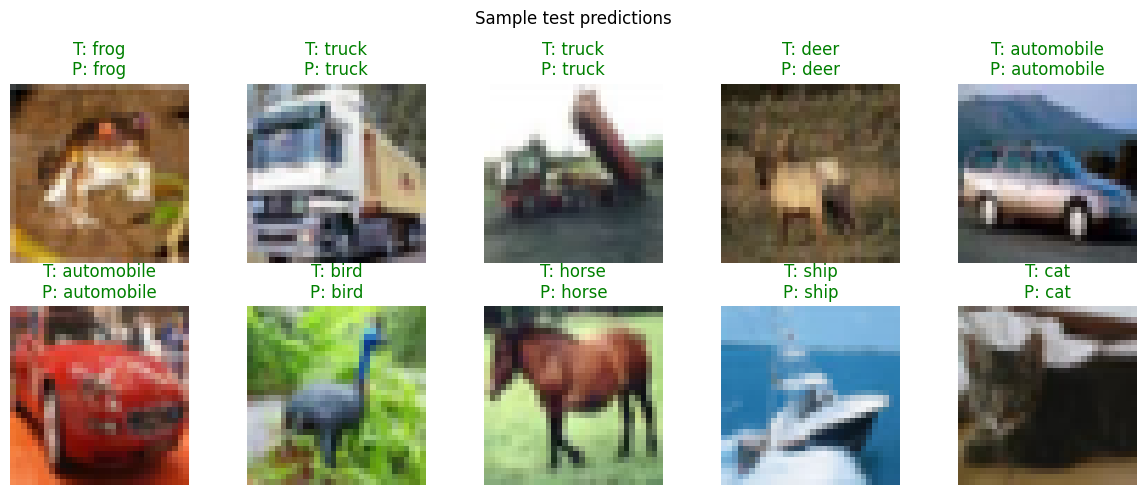

In [ ]:
# ================================================================
# CNN ON SIGN LANGUAGE MNIST (train.csv / test.csv)
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TRAIN_PATH = "/content/train.csv"     # change to your path
TEST_PATH = "/content/test.csv"       # change to your path

LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"  # no J or Z

# ================================================================
# STAGE A: LOADING AND PREPROCESSING THE IMAGE DATA
# ================================================================
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

# Labels skip 9 (J) and 25 (Z), so map them to 0..23 for to_categorical
unique_labels = sorted(train_df["label"].unique())
label_to_idx = {v: i for i, v in enumerate(unique_labels)}
NUM_CLASSES = len(unique_labels)                       # should be 24
class_names = [LETTERS[i] for i in range(NUM_CLASSES)]

def prepare(df):
    y = df["label"].map(label_to_idx).values
    X = df.drop(columns=["label"]).values.astype("float32") / 255.0
    X = X.reshape((-1, 28, 28, 1))                     # rows -> 28x28 grayscale images
    return X, to_categorical(y, NUM_CLASSES)

x_train, y_train = prepare(train_df)
x_test, y_test = prepare(test_df)
y_test_idx = y_test.argmax(axis=1)                     # integer labels for reports

print("Train:", x_train.shape, " Test:", x_test.shape)
print("Number of classes:", NUM_CLASSES)

# Sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(class_names[y_train[i].argmax()])
    plt.axis("off")
plt.suptitle("Sample Sign Language MNIST images")
plt.tight_layout()
plt.show()

# ================================================================
# STAGE B: DEFINING THE MODEL'S ARCHITECTURE
# ================================================================
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),                       # 28x28 -> 14x14
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),                       # 14x14 -> 7x7
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

# ================================================================
# STAGE C: TRAINING THE MODEL
# ================================================================
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(x_train, y_train,
                    validation_split=0.1,
                    epochs=15,
                    batch_size=128,
                    verbose=1)

# ================================================================
# STAGE D: ESTIMATING THE MODEL'S PERFORMANCE
# ================================================================
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print("\nClassification Report:")
print(classification_report(y_test_idx, y_pred, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(y_test_idx, y_pred)
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix (Sign Language MNIST CNN)")
plt.tight_layout()
plt.savefig("sign_mnist_cnn_confusion.png", dpi=150)
plt.show()

# Training curves
epochs_range = range(1, len(history.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(epochs_range, history.history["loss"], label="train_loss")
ax1.plot(epochs_range, history.history["val_loss"], label="val_loss")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True)
ax2.plot(epochs_range, history.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, history.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True)
fig.suptitle("CNN Training History on Sign Language MNIST")
plt.tight_layout()
plt.savefig("sign_mnist_cnn_training.png", dpi=150)
plt.show()

# Practise

In [ ]:
import tensorflow as tf

print("Tensorflow version: "+ tf.__version__)

Tensorflow version: 2.21.0


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/SEM7/cifar-10.csv")

In [ ]:
df.shape

(50000, 3073)

In [ ]:
label_col = "label"
y = df[label_col].values.astype("int64")
pixel_cols = [ c for c in df.columns if c!=label_col]
X = df[pixel_cols].values.astype("uint8")

In [ ]:
X = X.reshape((-1,3,32,32)).transpose(0,2,3,1)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)

In [ ]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [ ]:
from tensorflow.keras.utils import to_categorical

NUM_CLASSES = 10
y_train_cat = to_categorical(y_train,NUM_CLASSES)
y_test_cat = to_categorical(y_test,NUM_CLASSES)

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
  layers.Input(shape=(32,32,3)),

  layers.RandomFlip("horizontal"),
  layers.RandomTranslation(0.1,0.1),

  layers.Conv2D(32, (3,3), padding="same", activation="relu"),
  layers.Conv2D(32, (3,3), padding="same", activation="relu"),
  layers.MaxPooling2D((2,2)),
  layers.Dropout(0.25),

  layers.Conv2D(64, (3,3), padding="same", activation="relu"),
  layers.Conv2D(64, (3,3), padding="same", activation="relu"),
  layers.MaxPooling2D((2,2)),
  layers.Dropout(0.25),

  layers.Flatten(),
  layers.Dense(256, activation="relu"),
  layers.Dropout(0.5),
  layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_3 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,116,970 (4.26 MB)

 Trainable params: 1,116,970 (4.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train_cat,
                    validation_split=0.1,
                    epochs=10,
                    batch_size=128,
                    verbose=1)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 191s 653ms/step - accuracy: 0.3494 - loss: 1.7634 - val_accuracy: 0.5100 - val_loss: 1.3714
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 200s 646ms/step - accuracy: 0.4810 - loss: 1.4242 - val_accuracy: 0.5390 - val_loss: 1.3038
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 203s 650ms/step - accuracy: 0.5362 - loss: 1.2867 - val_accuracy: 0.5640 - val_loss: 1.2430
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 179s 636ms/step - accuracy: 0.5698 - loss: 1.1986 - val_accuracy: 0.6425 - val_loss: 1.0341
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 178s 632ms/step - accuracy: 0.6007 - loss: 1.1255 - val_accuracy: 0.6582 - val_loss: 0.9764
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 212s 668ms/step - accuracy: 0.6222 - loss: 1.0598 - val_accuracy: 0.6877 - val_loss: 0.9144
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 177s 628ms/step - accuracy: 0.6386 - loss: 1.0197 - val_accuracy: 0.7132 - val_loss: 0.8495
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 180s 639ms/step - accuracy: 0.6482 -

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat,verbose=0)
print(f"Test loss: {test_loss:.4f} Test acc: {test_acc:.4f}")

Test loss: 0.8086 Test acc: 0.7130


In [ ]:
predictions = model.predict(X_test, verbose=0)
y_pred = predictions.argmax(axis=1)

In [ ]:
from sklearn.metrics import classification_report
CLASS_NAMES=["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

              precision    recall  f1-score   support

    airplane       0.77      0.75      0.76      1000
  automobile       0.83      0.86      0.85      1000
        bird       0.74      0.50      0.60      1000
         cat       0.65      0.37      0.47      1000
        deer       0.77      0.56      0.65      1000
         dog       0.59      0.67      0.63      1000
        frog       0.60      0.90      0.72      1000
       horse       0.78      0.74      0.76      1000
        ship       0.86      0.84      0.85      1000
       truck       0.66      0.92      0.77      1000

    accuracy                           0.71     10000
   macro avg       0.72      0.71      0.70     10000
weighted avg       0.72      0.71      0.70     10000



In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

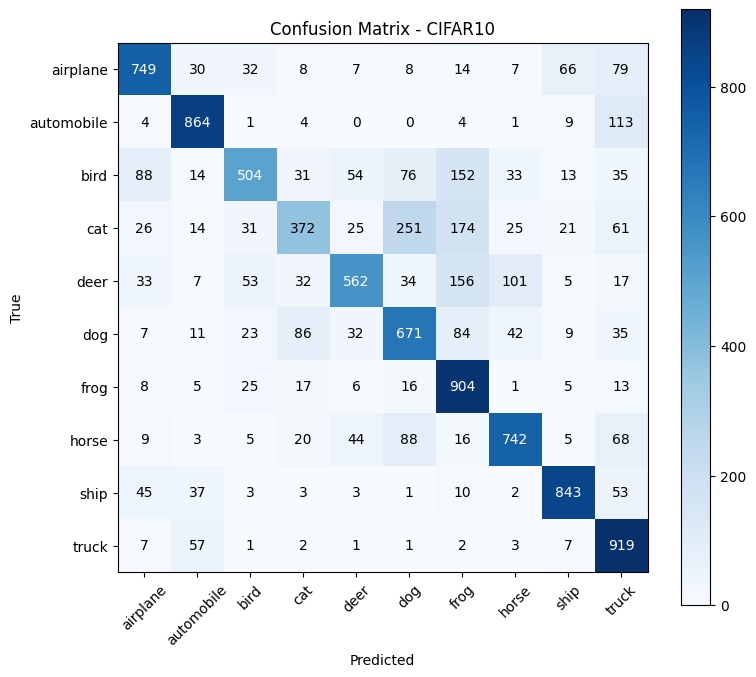

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
plt.yticks(range(NUM_CLASSES),CLASS_NAMES)
for i in range(NUM_CLASSES):
  for j in range(NUM_CLASSES):
    plt.text(j,i,cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - CIFAR10")
plt.tight_layout()
plt.show()

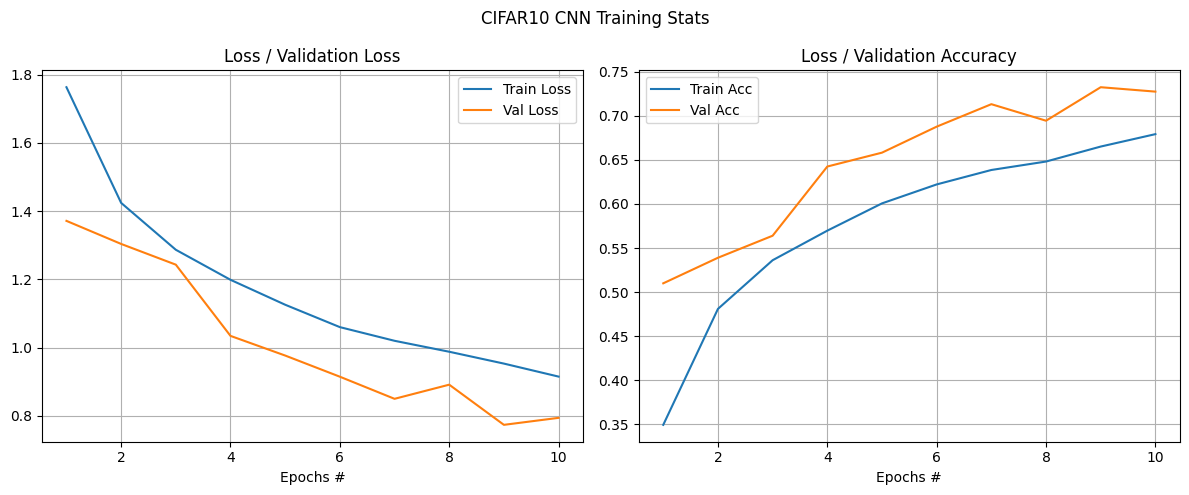

In [ ]:
epochs_range = range(1,len(history.history["loss"])+1)
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))
ax1.plot(epochs_range, history.history["loss"], label="Train Loss")
ax1.plot(epochs_range, history.history["val_loss"], label="Val Loss")
ax1.legend();ax1.set_title("Loss / Validation Loss");ax1.set_xlabel("Epochs #");ax1.grid(True);
ax2.plot(epochs_range, history.history["accuracy"], label="Train Acc")
ax2.plot(epochs_range, history.history["val_accuracy"], label="Val Acc")
ax2.legend();ax2.set_title("Loss / Validation Accuracy");ax2.set_xlabel("Epochs #");ax2.grid(True);
fig.suptitle("CIFAR10 CNN Training Stats")
plt.tight_layout()
plt.show()